# <center><b>PROJETO FINAL BOOTCAMP CIÊNCIA DE DADOS E INTELIGÊNCIA ARTIFICIAL</b></center>
#### <center><b>Candidadto: Cláudio da Cunha Machado<b/></center>

### <b>ENTENDIMENTO DO PROBLEMA</b>

O objetivo deste projeto é desenvolver um sistema inteligente para classificar defeitos em chapas de aço inoxidável com base em 31
indicadores geométricos e estatístico. O sistemma deve prever a classe do defeito e retornar probabilidades associadas,
além de gerar insights e visualizações.

A metodologia a ser utilizada é consiste em Classificação Multiclasse, visto que o problema envolve 7 classes de defeitos (6 específicas + "outros"), tornando a modelagem multiclasse a abordagem mais adequada. A metodologia justifica-se pelofato de que cada amostra pertence a apenas uma classe (não há sobreposição de rótulos), descartando a necessidade de multirrótulo.

### <b>ANÁLISE EXPLORATÓRIA</b>

In [1]:
# Importar bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Carregar o dataset de treino
try:
    df_train = pd.read_csv('bootcamp_train.csv')
    print("Dataset de treino carregado com sucesso.")
except FileNotFoundError:
    print("Erro: Arquivo Bootcamp_train.csv não encontrado.")
    # Adicionar código para lidar com o erro, talvez sair ou carregar de outro local

Dataset de treino carregado com sucesso.


In [3]:
# Exibir as primeiras linhas do dataset
print("\nPrimeiras 5 linhas do dataset de treino:")
print(df_train.head())


Primeiras 5 linhas do dataset de treino:
   id  x_minimo  x_maximo  y_minimo  y_maximo  peso_da_placa  area_pixels  \
0   0       154     169.0    260124    260136            100           75   
1   1      1121    -186.0   1789332   1789337            100         -206   
2   2        41     216.0   2708878   2708939            100         6298   
3   3       129     157.0     86408     86427            100          276   
4   4       436     442.0   4959398    530985            100           63   

   perimetro_x  perimetro_y  soma_da_luminosidade  ...  \
0           27           17                9948.0  ...   
1            9         -194                2240.0  ...   
2          275          134              654634.0  ...   
3           39           26               33858.0  ...   
4           17           17                6374.0  ...   

   indice_de_luminosidade  sigmoide_das_areas minimo_da_luminosidade falha_1  \
0                  0.0362              0.3068                    1

In [4]:
# Verificar informações gerais do dataset (tipos de dados, valores não nulos)
print("\nInformações do dataset:")
df_train.info()


Informações do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3390 entries, 0 to 3389
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            3390 non-null   int64  
 1   x_minimo                      3390 non-null   int64  
 2   x_maximo                      3334 non-null   float64
 3   y_minimo                      3390 non-null   int64  
 4   y_maximo                      3390 non-null   int64  
 5   peso_da_placa                 3390 non-null   int64  
 6   area_pixels                   3390 non-null   int64  
 7   perimetro_x                   3390 non-null   int64  
 8   perimetro_y                   3390 non-null   int64  
 9   soma_da_luminosidade          3290 non-null   float64
 10  maximo_da_luminosidade        3292 non-null   float64
 11  comprimento_do_transportador  3390 non-null   int64  
 12  tipo_do_aço_A300              3390 no

In [5]:
# Verificar estatísticas descritivas das colunas numéricas
print("\nEstatísticas descritivas do dataset:")
print(df_train.describe())


Estatísticas descritivas do dataset:
                id      x_minimo    x_maximo      y_minimo      y_maximo  \
count  3390.000000   3390.000000  3334.00000  3.390000e+03  3.390000e+03   
mean   1694.500000    995.507375   605.90012  2.692640e+06  1.592301e+06   
std     978.753033   1796.737709   548.07724  5.625693e+06  1.821345e+06   
min       0.000000    -11.000000  -186.00000 -2.000000e+01 -1.660000e+02   
25%     847.250000     41.000000   179.00000  3.934352e+05  3.407380e+05   
50%    1694.500000    614.000000   544.00000  1.265462e+06  1.128297e+06   
75%    2541.750000   1187.500000  1090.00000  2.555025e+06  2.184335e+06   
max    3389.000000  15266.000000  1713.00000  1.041366e+08  1.291709e+07   

       peso_da_placa    area_pixels  perimetro_x   perimetro_y  \
count         3390.0    3390.000000  3390.000000   3390.000000   
mean           100.0    1566.317699    66.733923     47.261062   
std              0.0    4337.683975   195.092105    336.794632   
min          

In [6]:
# Identificar colunas de rótulo (falhas)
label_cols = ['falha_1', 'falha_2', 'falha_3', 'falha_4', 'falha_5', 'falha_6', 'falha_outros']

In [7]:
# Verificar a presença de valores ausentes ou atípicos (como os negativos por exemplo)
print("\nValores únicos nas colunas:")
for col in df_train.columns:
    # Imprimir valores únicos para colunas com poucos valores (ex: tipo_do_aço)
    if df_train[col].nunique() < 20:
         print(f"- {col}: {df_train[col].unique()}")


Valores únicos nas colunas:
- peso_da_placa: [100]
- tipo_do_aço_A300: ['Não' 'não' '1' 'Sim' 'sim' '0' 'N' '-']
- tipo_do_aço_A400: ['sim' 'Sim' 'Não' 'não' nan '1' '0' 'S' 'nao']
- indice_global_externo: [0.  1.  nan 0.5]
- falha_1: ['False' '0' '1' 'True' 'nao' 'S']
- falha_2: ['0' 'False' 'True' 'y' '1' 'S']
- falha_3: [False  True]
- falha_4: ['False' 'True' 'nao' '0' 'S' '1']
- falha_5: ['não' 'Não' 'Sim' 'sim']
- falha_6: [False  True]
- falha_outros: ['Sim' 'Não']


In [8]:
# Análise de valores específicos que parecem indicar dados faltantes ou erros
missing_values_indicators = [-11, -20, -166, -194, -214, -229] # Baseado nas amostras
print("\nContagem de valores atípicos/faltantes comuns nas colunas:")
for col in df_train.columns:
    for val in missing_values_indicators:
        count = (df_train[col] == val).sum()
        if count > 0:
            print(f"- Coluna '{col}' possui {count} ocorrências do valor {val}")


Contagem de valores atípicos/faltantes comuns nas colunas:
- Coluna 'x_minimo' possui 339 ocorrências do valor -11
- Coluna 'y_minimo' possui 339 ocorrências do valor -20
- Coluna 'y_maximo' possui 339 ocorrências do valor -166
- Coluna 'perimetro_x' possui 339 ocorrências do valor -229
- Coluna 'perimetro_y' possui 339 ocorrências do valor -194
- Coluna 'comprimento_do_transportador' possui 339 ocorrências do valor -214


In [9]:
# Analisar a distribuição das classes de falha (rótulos)
print("\nDistribuição das classes de falha:")
for col in label_cols:
    print(f"- {col}:")
    print(df_train[col].value_counts())
    print("-" * 20)


Distribuição das classes de falha:
- falha_1:
falha_1
False    2992
True      265
nao        62
0          61
1           5
S           5
Name: count, dtype: int64
--------------------
- falha_2:
falha_2
False    3064
True      249
0          62
y           5
1           5
S           5
Name: count, dtype: int64
--------------------
- falha_3:
falha_3
False    2741
True      649
Name: count, dtype: int64
--------------------
- falha_4:
falha_4
False    3145
True      112
nao        65
0          64
S           2
1           2
Name: count, dtype: int64
--------------------
- falha_5:
falha_5
Não    1977
não    1317
Sim      58
sim      38
Name: count, dtype: int64
--------------------
- falha_6:
falha_6
False    2584
True      806
Name: count, dtype: int64
--------------------
- falha_outros:
falha_outros
Não    2206
Sim    1184
Name: count, dtype: int64
--------------------


### <b>VISUALIZAÇÃO DOS DADOS</B>

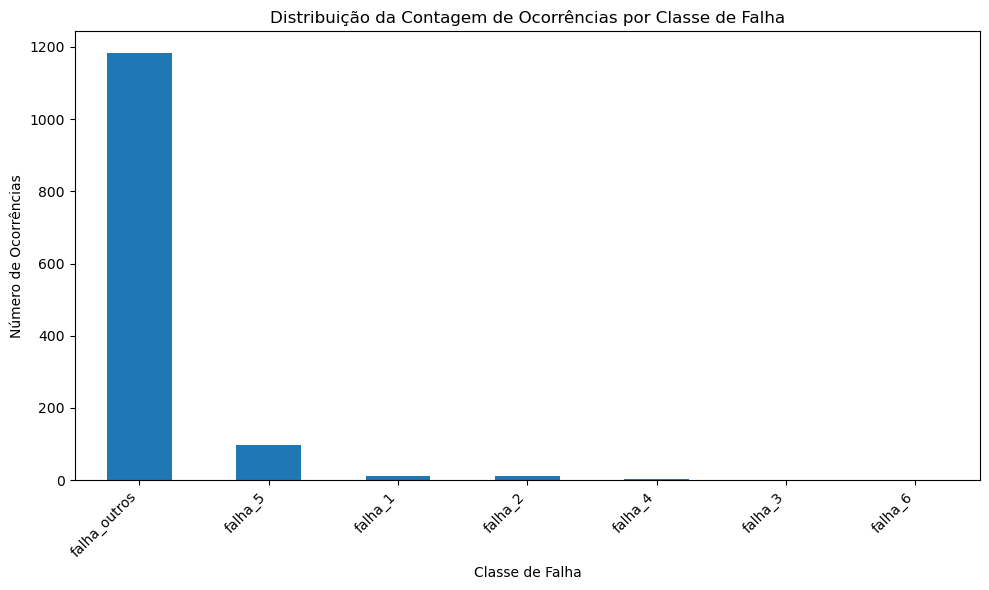

In [10]:
# Definir as colunas que representam as classes de falha com base na descrição dos dados [13, 14]
label_cols = ['falha_1', 'falha_2', 'falha_3', 'falha_4', 'falha_5', 'falha_6', 'falha_outros']

# Mapear os valores encontrados nos dados para 0 ou 1
# Baseado nos dados de exemplo [1-11], 'Sim', 'sim', 'S', '1' indicam a presença (1)
# e 'Não', 'não', '0' indicam a ausência (0). Outros valores podem precisar de tratamento,
# mas o erro UFuncTypeError é causado pela mistura de strings e ints aqui.
mapping = {'Sim': 1, 'sim': 1, 'S': 1, '1': 1,
           'Não': 0, 'não': 0, '0': 0}

# Aplicar o mapeamento e converter para tipo inteiro
# Itere pelas colunas de falha e aplique o mapeamento e conversão
for col in label_cols:
    # Usar .map() para aplicar o dicionário. Valores que não estão no dicionário
    # se tornarão NaN. Podemos preencher esses NaNs com 0, assumindo que
    # qualquer valor não mapeado explicitamente para 1 significa ausência de falha,
    # ou investigar esses valores. Para corrigir o erro UFuncTypeError, o mapeamento é essencial.
    df_train[col] = df_train[col].map(mapping).fillna(0).astype(int) # Preencher NaNs com 0 e converter para int

# Visualização da distribuição das classes de falha (o código original agora funcionará)
plt.figure(figsize=(10, 6))
df_train[label_cols].sum().sort_values(ascending=False).plot(kind='bar')
plt.title('Distribuição da Contagem de Ocorrências por Classe de Falha')
plt.xlabel('Classe de Falha')
plt.ylabel('Número de Ocorrências')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

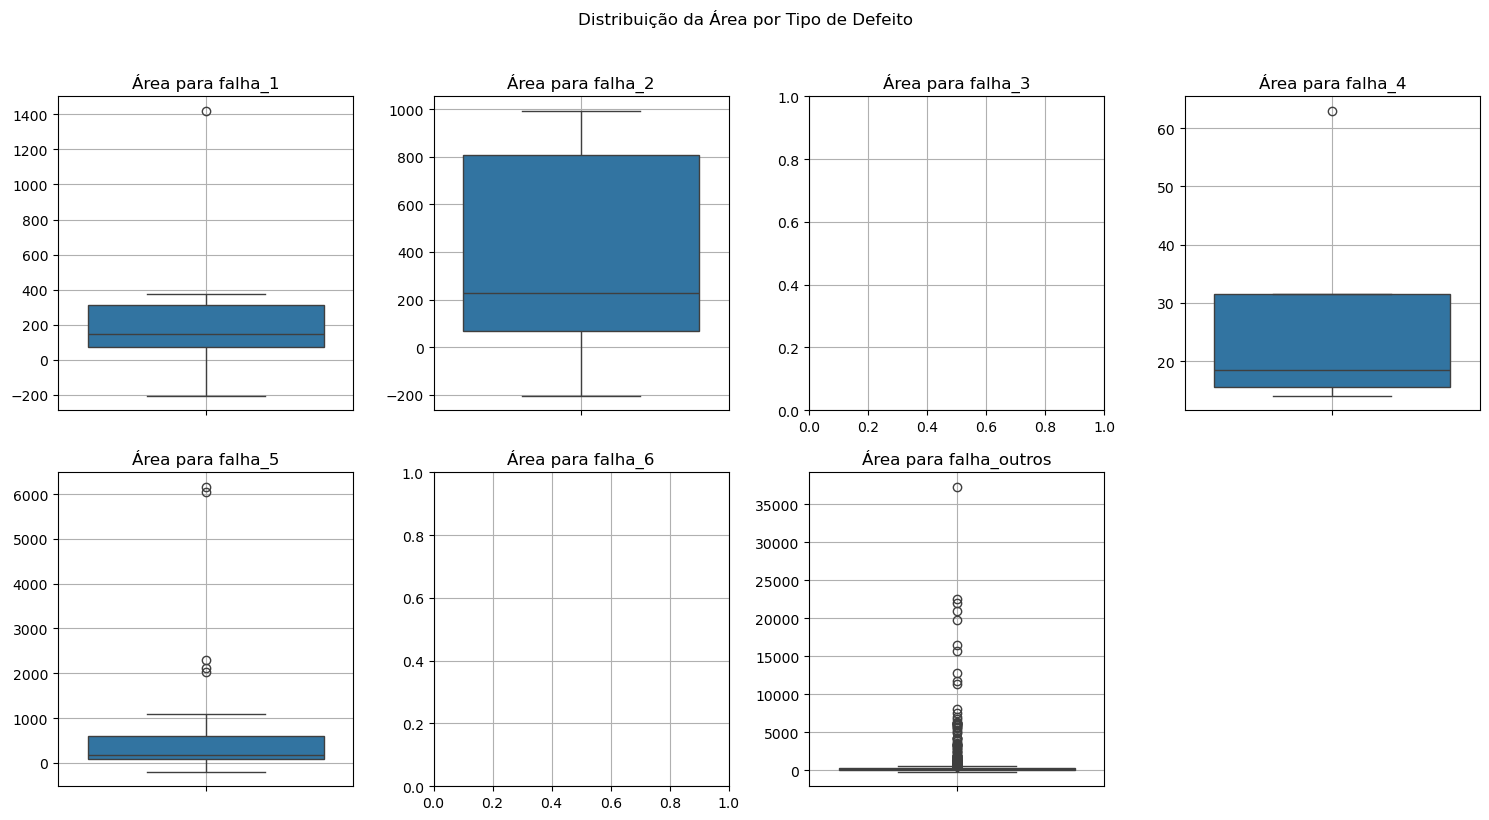

In [75]:
# Distribuição da área por tipo de defeito
falhas = ['falha_1', 'falha_2', 'falha_3', 'falha_4', 'falha_5', 'falha_6', 'falha_outros']
plt.figure(figsize=(15, 8))

for i, falha in enumerate(falhas, 1):
    plt.subplot(2, 4, i)
    df_filtrado = df_train[df_train[falha] == 1]
    sns.boxplot(data=df_filtrado, y='area_pixels')
    plt.title(f'Área para {falha}')
    plt.ylabel('')
    plt.grid(True)

plt.suptitle('Distribuição da Área por Tipo de Defeito', y=1.02)
plt.tight_layout()
plt.show()

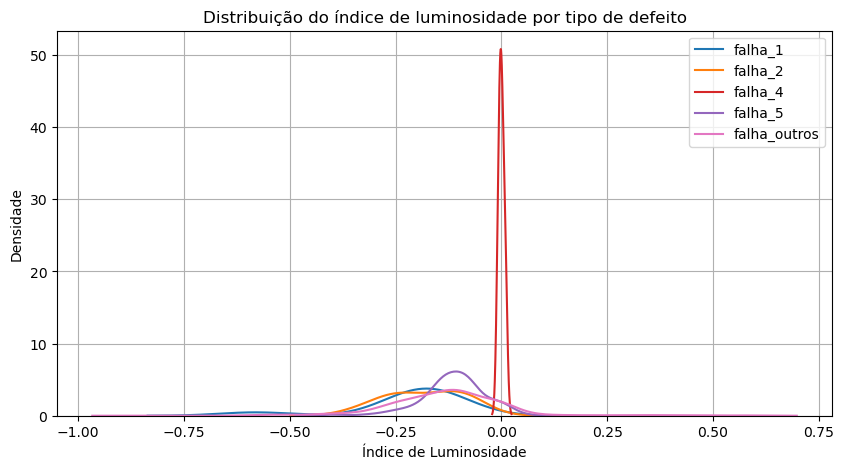

In [78]:
# Distribuição do Índice de Luminosidade por tipo de defeito
plt.figure(figsize=(10, 5))
for i in range(1, 7):
    sns.kdeplot(df_train[df_train[f'falha_{i}'] == 1]['indice_de_luminosidade'], label=f'falha_{i}')
sns.kdeplot(df_train[df_train['falha_outros'] == 1]['indice_de_luminosidade'], label='falha_outros')
plt.title('Distribuição do índice de luminosidade por tipo de defeito')
plt.xlabel('Índice de Luminosidade')
plt.ylabel('Densidade')
plt.legend()
plt.grid(True)
plt.show()

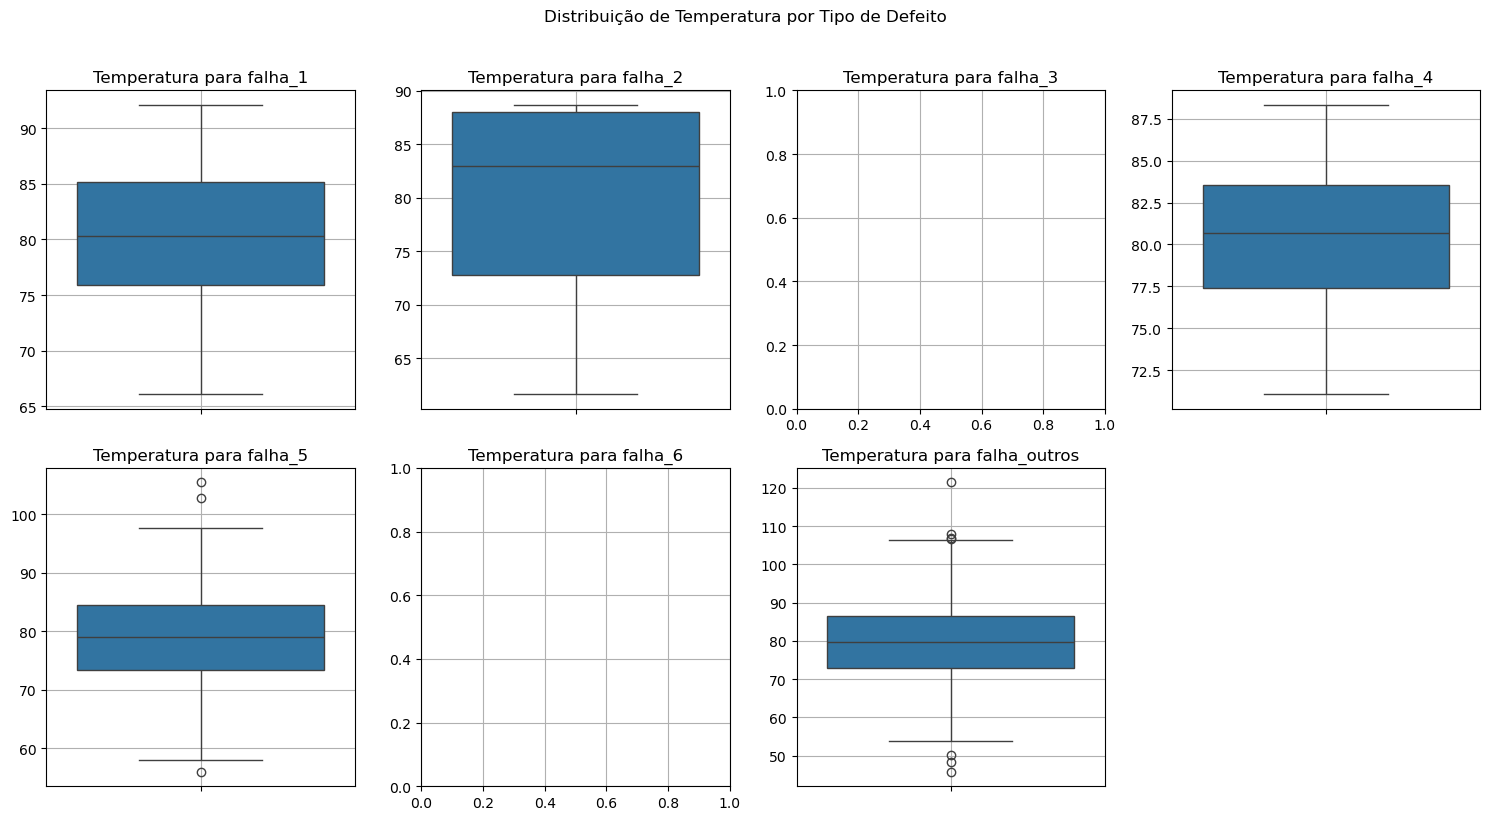

In [80]:
# Distribuição de Temperatura por tipo de defeito
falhas = ['falha_1', 'falha_2', 'falha_3', 'falha_4', 'falha_5', 'falha_6', 'falha_outros']
plt.figure(figsize=(15, 8))

for i, falha in enumerate(falhas, 1):
    plt.subplot(2, 4, i)
    df_temp = df_train[df_train[falha] == 1]
    sns.boxplot(data=df_temp, y='temperatura')
    plt.title(f'Temperatura para {falha}')
    plt.ylabel('')
    plt.grid(True)

plt.suptitle('Distribuição de Temperatura por Tipo de Defeito', y=1.02)
plt.tight_layout()
plt.show()

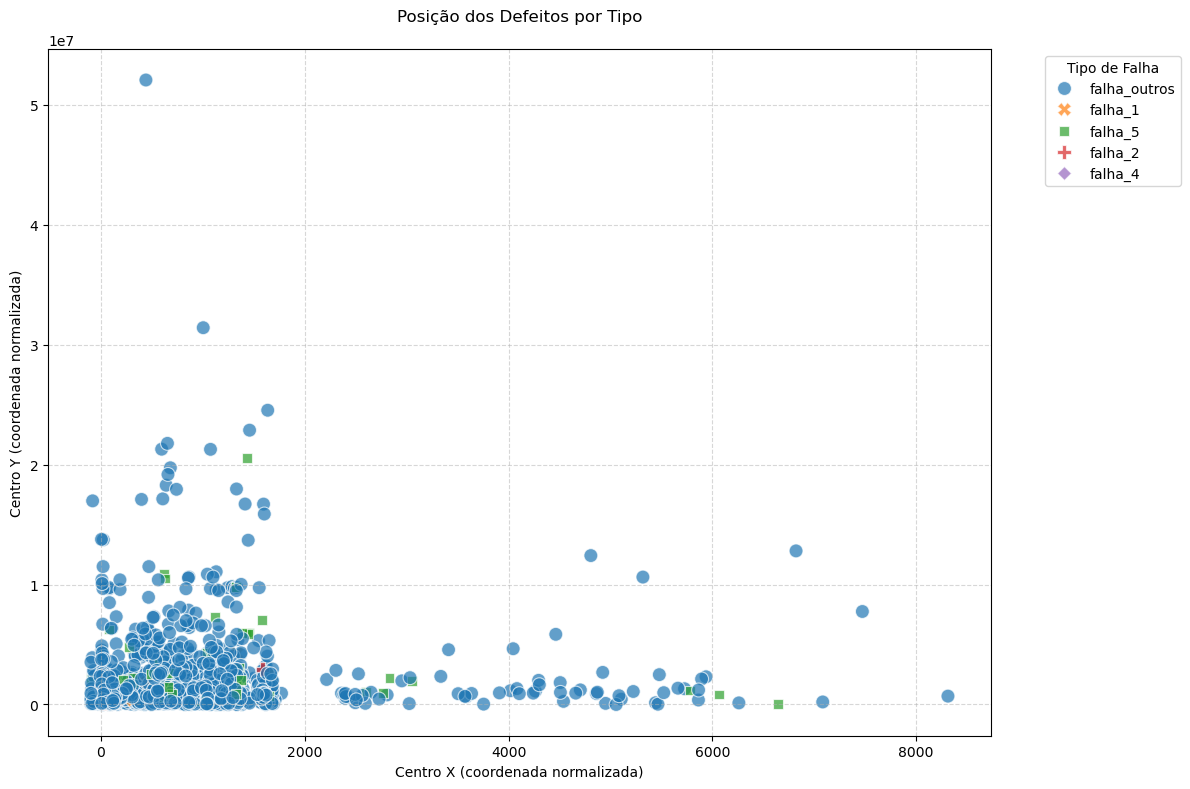

In [79]:
# Posição dos defeitos por tipo
# Calcular coordenadas centrais
df_train['x_centro'] = (df_train['x_minimo'] + df_train['x_maximo']) / 2
df_train['y_centro'] = (df_train['y_minimo'] + df_train['y_maximo']) / 2

# Criar uma coluna combinada para todos os tipos de falha
df_train['tipo_falha'] = 'sem_defeito'  # Inicializa como sem defeito

# Atualiza com os tipos de falha presentes
for i in range(1, 7):
    df_train.loc[df_train[f'falha_{i}'] == 1, 'tipo_falha'] = f'falha_{i}'
df_train.loc[df_train['falha_outros'] == 1, 'tipo_falha'] = 'falha_outros'

# Filtrar apenas linhas com defeitos
df_defeitos = df_train[df_train['tipo_falha'] != 'sem_defeito']

# Plotar
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df_defeitos,
    x='x_centro',
    y='y_centro',
    hue='tipo_falha',
    palette='tab10',  # Paleta com cores distintas
    style='tipo_falha',  # Diferentes marcadores para cada tipo
    s=100,  # Tamanho dos pontos
    alpha=0.7  # Transparência
)

plt.title('Posição dos Defeitos por Tipo', pad=20)
plt.xlabel('Centro X (coordenada normalizada)')
plt.ylabel('Centro Y (coordenada normalizada)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Tipo de Falha')
plt.tight_layout()
plt.show()

#### <b>PRÉ-PROCESSAMENTO DE DADOS</b>

Valores negativos não representam medições físicas válidas para as características geométricas e estatísticas das chapas. A presença consistente de 339 ocorrências desses mesmos valores atípicos em colunas específicas reforça a hipótese levantada pelo seu código: esses valores parecem ser indicadores de dados faltantes ou erros na coleta/extração das informações. A seguir, faremos o tratammento destes dados.

In [11]:
# Tratar valores atípicos/faltantes (substituir por NaN e depois decidir estratégia)
# Podemos substituir os valores negativos por NaN para que sejam reconhecidos como faltantes
df_train_processed = df_train.copy()
missing_values_indicators = [-11, -20, -166, -194, -214, -229]

for val in missing_values_indicators:
    df_train_processed = df_train_processed.replace(val, np.nan)

print("\nInformações do dataset após substituir valores atípicos por NaN:")
df_train_processed.info()


Informações do dataset após substituir valores atípicos por NaN:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3390 entries, 0 to 3389
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            3390 non-null   int64  
 1   x_minimo                      3051 non-null   float64
 2   x_maximo                      3334 non-null   float64
 3   y_minimo                      3051 non-null   float64
 4   y_maximo                      3051 non-null   float64
 5   peso_da_placa                 3390 non-null   int64  
 6   area_pixels                   3390 non-null   int64  
 7   perimetro_x                   3051 non-null   float64
 8   perimetro_y                   3051 non-null   float64
 9   soma_da_luminosidade          3290 non-null   float64
 10  maximo_da_luminosidade        3292 non-null   float64
 11  comprimento_do_transportador  3051 non-null   float64
 

In [15]:
#Visualização de valores vazios
(df_train.isnull().sum()/df_train.shape[0]).sort_values(ascending=False).head(10)

soma_da_luminosidade         0.029499
maximo_da_luminosidade       0.028909
tipo_do_aço_A400             0.022419
indice_global_externo        0.017404
x_maximo                     0.016519
indice_de_luminosidade       0.014749
espessura_da_chapa_de_aço    0.012094
index_quadrado               0.010619
log_das_areas                0.000000
log_indice_x                 0.000000
dtype: float64

Os ados faltantes são minoritários, já que nenhuma coluna ultrapassa 3% de valores vazios. Sendo assim, o impacto é limitado.

In [17]:
# Verificando se as mesmas linhas têm valores faltantes em múltiplas colunas
missing_mask = df_train[['soma_da_luminosidade', 'maximo_da_luminosidade', 'tipo_do_aço_A400']].isnull()
print(missing_mask.sum(axis=1).value_counts())

0    3123
1     260
2       7
Name: count, dtype: int64


Apenas 267 linhas (260 + 7) têm algum valor faltante, em um total de 3123 + 260 + 7 = 3390 linhas (~7.8% do dataset). Impacto limitado!

In [21]:
# Preenchimento de NAs (sem warnings)
df_train['soma_da_luminosidade'] = df_train['soma_da_luminosidade'].fillna(df_train['soma_da_luminosidade'].median())
df_train['maximo_da_luminosidade'] = df_train['maximo_da_luminosidade'].fillna(df_train['maximo_da_luminosidade'].median())
df_train['tipo_do_aço_A400'] = df_train['tipo_do_aço_A400'].fillna(df_train['tipo_do_aço_A400'].mode()[0])

# Verificação final (deve retornar 0 para todas as colunas)
print(df_train[['soma_da_luminosidade', 'maximo_da_luminosidade', 'tipo_do_aço_A400']].isnull().sum())

soma_da_luminosidade      0
maximo_da_luminosidade    0
tipo_do_aço_A400          0
dtype: int64


In [22]:
# Verificar se ainda existem NaNs
print("\nVerificando NaNs após imputação:")
print(df_train_processed.isnull().sum().sum()) # Soma total de NaNs


Verificando NaNs após imputação:
262


In [25]:
# Lista específica de colunas com valores nulos a tratar
cols_com_na = ['x_maximo', 'espessura_da_chapa_de_aço', 'index_quadrado', 
               'indice_global_externo', 'indice_de_luminosidade']

# Preenchimento de cada coluna individualmente com sua própria mediana
for col in cols_com_na:
    df_train[col] = df_train[col].fillna(df_train[col].median())

# Verificação pós-tratamento final
print("Valores nulos após tratamento:")
print(df_train[cols_com_na].isnull().sum())
print("Total de NAs no DataFrame:", df_train.isnull().sum().sum())

Valores nulos após tratamento:
x_maximo                     0
espessura_da_chapa_de_aço    0
index_quadrado               0
indice_global_externo        0
indice_de_luminosidade       0
dtype: int64
Total de NAs no DataFrame: 0


In [26]:
# Remover a coluna 'id' pois não é uma feature para o modelo
df_train_processed = df_train_processed.drop('id', axis=1)
print("\nColuna 'id' removida.")


Coluna 'id' removida.


In [27]:
# Separar features (X) e rótulos (y)
X = df_train_processed.drop(label_cols, axis=1)
y = df_train_processed[label_cols]

In [30]:
from sklearn.preprocessing import StandardScaler

# Selecionar apenas colunas numéricas
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Verificar se há colunas não numéricas
non_numeric_cols = X.select_dtypes(exclude=['int64', 'float64']).columns
if len(non_numeric_cols) > 0:
    print(f"Atenção: Colunas não numéricas serão removidas: {list(non_numeric_cols)}")

# Escalar apenas as colunas numéricas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[numeric_cols])

# Converter de volta para DataFrame mantendo os nomes das colunas
X_processed = pd.DataFrame(X_scaled, columns=numeric_cols)

# pcional: Adicionar colunas categóricas originais (não escaladas)
# X_processed = pd.concat([X_processed, X[non_numeric_cols]], axis=1)

print("\nDados prontos para modelagem:")
print("Formato de X:", X_processed.shape)
print("Colunas processadas:", X_processed.columns.tolist())
print("Formato de y:", y.shape)

Atenção: Colunas não numéricas serão removidas: ['tipo_do_aço_A300', 'tipo_do_aço_A400']

Dados prontos para modelagem:
Formato de X: (3390, 29)
Colunas processadas: ['x_minimo', 'x_maximo', 'y_minimo', 'y_maximo', 'peso_da_placa', 'area_pixels', 'perimetro_x', 'perimetro_y', 'soma_da_luminosidade', 'maximo_da_luminosidade', 'comprimento_do_transportador', 'espessura_da_chapa_de_aço', 'temperatura', 'index_de_bordas', 'index_vazio', 'index_quadrado', 'index_externo_x', 'indice_de_bordas_x', 'indice_de_bordas_y', 'indice_de_variacao_x', 'indice_de_variacao_y', 'indice_global_externo', 'log_das_areas', 'log_indice_x', 'log_indice_y', 'indice_de_orientaçao', 'indice_de_luminosidade', 'sigmoide_das_areas', 'minimo_da_luminosidade']
Formato de y: (3390, 7)


#### <b>MODELAGEM E TREINAMENTO</b>

In [32]:
# Dividir os dados em conjuntos de treino e validação
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_val, y_train, y_val = train_test_split(X_processed, y, test_size=0.2, random_state=42) # Ajuste test_size conforme necessário

print("\nDados divididos para treino e validação:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


Dados divididos para treino e validação:
X_train: (2712, 29)
y_train: (2712, 7)
X_val: (678, 29)
y_val: (678, 7)


In [34]:
# Escolher e treinar um modelo multilabel
# RandomForestClassifier suporta multilabel diretamente
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier 

In [39]:
# Modelo (RandomForest)
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

In [45]:
# Treinamento
model.fit(X_train, y_train)

# Avaliação
from sklearn.metrics import classification_report, f1_score

y_pred = model.predict(X_val)
print("\nRelatório de Classificação:\n", classification_report(y_val, y_pred, target_names=y.columns))
print("F1-Score (macro):", f1_score(y_val, y_pred, average='macro'))

# 4. Validação Cruzada (opcional mas recomendado)
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(model, X_processed, y, cv=5, scoring='f1_macro')
print("\nValidação Cruzada (F1-macro):", cv_scores.mean())

C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Letícia\anaconda3\Lib\site


Relatório de Classificação:
               precision    recall  f1-score   support

     falha_1       0.00      0.00      0.00         2
     falha_2       0.00      0.00      0.00         3
     falha_3       0.00      0.00      0.00         0
     falha_4       0.00      0.00      0.00         0
     falha_5       0.75      0.32      0.44        19
     falha_6       0.00      0.00      0.00         0
falha_outros       0.65      0.40      0.49       215

   micro avg       0.65      0.38      0.48       239
   macro avg       0.20      0.10      0.13       239
weighted avg       0.64      0.38      0.48       239
 samples avg       0.13      0.13      0.13       239

F1-Score (macro): 0.13368198917331867


C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Letí


Validação Cruzada (F1-macro): 0.10181250825453236


C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### <b>AVALIAÇÃO DO MODELO</b>

In [49]:
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier

# Criar e treinar o modelo multioutput
base_model = RandomForestClassifier(random_state=42)
multioutput_model = MultiOutputClassifier(base_model)

# Treinar o modelo
multioutput_model.fit(X_train, y_train)  # Esta etapa estava faltando

# Fazer predições
try:
    # Predições de classe
    y_pred_val = multioutput_model.predict(X_val)
    
    # Probabilidades (formato específico para MultiOutputClassifier)
    y_pred_proba_val = multioutput_model.predict_proba(X_val)
    
    print("Predições realizadas com sucesso!")
    print("Formato das probabilidades:", [p.shape for p in y_pred_proba_val])

except Exception as e:
    print(f"Erro durante as predições: {str(e)}")

Predições realizadas com sucesso!
Formato das probabilidades: [(678, 2), (678, 2), (678, 1), (678, 2), (678, 2), (678, 1), (678, 2)]


In [72]:
# Avaliar usando métricas apropriadas para multilabel
# F1-score, Precision, Recall
# 'micro' ou 'macro' average são comuns para multilabel
f1_micro = f1_score(y_val, y_pred_val, average='micro')
f1_macro = f1_score(y_val, y_pred_val, average='macro')
precision_micro = precision_score(y_val, y_pred_val, average='micro')
recall_micro = recall_score(y_val, y_pred_val, average='micro')

print(f"\nMétricas de Avaliação (Validação):")
print(f"F1-Score (Micro): {f1_micro:.4f}")
print(f"F1-Score (Macro): {f1_macro:.4f}")
print(f"Precision (Micro): {precision_micro:.4f}")
print(f"Recall (Micro): {recall_micro:.4f}")



Métricas de Avaliação (Validação):
F1-Score (Micro): 0.5205
F1-Score (Macro): 0.1213
Precision (Micro): 0.6136
Recall (Micro): 0.4519


C:\Users\Letícia\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### <b>PREDIÇÃO NO CONJUNTO DE TESTE</b>

In [59]:
# Carregar o dataset de teste
try:
    df_test = pd.read_csv('bootcamp_test.csv')
    print("\nDataset de teste carregado com sucesso.")
except FileNotFoundError:
    print("Erro: Arquivo Bootcamp_test.csv não encontrado.")



Dataset de teste carregado com sucesso.


In [60]:
# Aplicar o mesmo pré-processamento usado no treino
# Tratar valores atípicos/faltantes
df_test_processed = df_test.copy()
for val in missing_values_indicators: 
    df_test_processed = df_test_processed.replace(val, np.nan)


In [62]:
imputation_values = {}
for col in cols_with_nan:
     imputation_values[col] = df_test[col].replace(missing_values_indicators, np.nan).median() # Mediana do treino (original, sem remover 'id')

for col in cols_with_nan:
    df_test_processed[col] = df_test_processed[col].fillna(imputation_values[col])
    print(f"NaNs na coluna de teste '{col}' imputados com a mediana do treino ({imputation_values[col]}).")


NaNs na coluna de teste 'tipo_do_aço_A400' imputados com a mediana do treino (1.0).
NaNs na coluna de teste 'espessura_da_chapa_de_aço' imputados com a mediana do treino (70.0).
NaNs na coluna de teste 'index_quadrado' imputados com a mediana do treino (0.5385).
NaNs na coluna de teste 'indice_global_externo' imputados com a mediana do treino (1.0).
NaNs na coluna de teste 'indice_de_luminosidade' imputados com a mediana do treino (-0.1435).


In [63]:
# Armazenar IDs para o arquivo de submissão/API
test_ids = df_test_processed['id']

In [64]:
# Remover a coluna 'id'
df_test_processed = df_test_processed.drop('id', axis=1)
print("\nColuna 'id' removida do dataset de teste.")


Coluna 'id' removida do dataset de teste.


In [65]:
# Selecionar as colunas de features, que devem ser as mesmas do treino
X_test = df_test_processed[feature_cols] # Usar a lista 'feature_cols' definida na Etapa 4

In [67]:
# Fazer predições (classes) no conjunto de teste
test_predictions = multioutput_model.predict(X_test_processed) # Usar o modelo final treinado

NameError: name 'X_test_processed' is not defined

In [69]:
#Fazer predições de probabilidade no conjunto de teste
test_probabilities_combined = np.column_stack([model.predict_proba(X_test_processed)[:, 1] for model in multioutput_model.estimators_])

NameError: name 'X_test_processed' is not defined

In [ ]:
# As colunas de probabilidade correspondem a label_cols
prob_cols = [f'{label}_proba' for label in label_cols]
df_test_probabilities = pd.DataFrame(test_probabilities_combined, columns=prob_cols)

In [70]:
# Preparar arquivo para submissão na API
df_submission = pd.DataFrame({'id': test_ids})

In [ ]:
# Adicionar as predições binárias (0 ou 1)
df_test_predictions = pd.DataFrame(test_predictions, columns=label_cols)
df_submission = pd.concat([df_submission, df_test_predictions], axis=1)

In [ ]:
# Adicionar as probabilidades
df_submission = pd.concat([df_submission, df_test_probabilities], axis=1)

print("\nDataFrame de submissão (Exemplo):")
print(df_submission.head())

In [71]:
# Salvar o arquivo de submissão
df_submission.to_csv('submission.csv', index=False)
print("\nArquivo de submissão 'submission.csv' gerado.")


Arquivo de submissão 'submission.csv' gerado.


### <b>FIM DO PROJETO</B>